In [1]:
import pandas as pd

df = pd.read_excel('./data/equator_pacific.xlsx')

In [2]:
df

,Age(Ma),Depth(m),Carbon_CaCO3 (wt%),Dry Density (g/cm3),SR(m/Ma),CAR(mg/cm2/kyr),Paledepth,Hole
0,0.000643,0.01,78.0,0.646779,15.551609,784.559096,3873.551399,572A
1,0.010867,19.20,0.0,0.808950,58.058054,0.000000,4158.102362,495
2,0.011256,0.30,5.1,0.223000,26.745610,30.417782,3709.811273,845A
3,0.015872,0.33,73.6,0.500000,20.862285,767.732078,3786.575383,850A
4,0.018605,1.50,2.3,1.128233,80.913455,209.965290,5934.445039,499
...,...,...,...,...,...,...,...,...
5006,81.721702,402.16,74.5,0.655248,2.075855,101.334878,5303.843803,199
5007,81.973687,120.25,67.7,0.947108,2.725044,174.727745,4541.536703,170
5008,82.528244,120.59,1.1,0.949959,2.993129,3.127685,4531.920214,170
5009,99.977017,185.23,7.4,0.951720,1.056000,7.437121,4180.559000,170


In [3]:
age = df['Age(Ma)']
CAR = df['CAR(mg/cm2/kyr)']

In [6]:
age

0         0.000643
1         0.010867
2         0.011256
3         0.015872
4         0.018605
           ...    
5006     81.721702
5007     81.973687
5008     82.528244
5009     99.977017
5010    101.340128
Name: Age(Ma), Length: 5011, dtype: float64

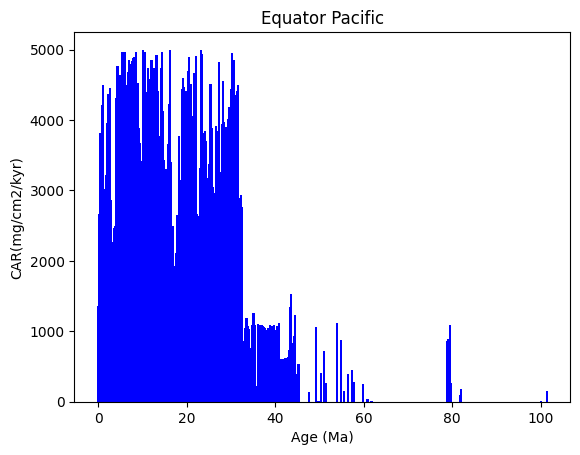

In [4]:
import matplotlib.pyplot as plt

plt.bar(age, CAR, width=0.5, color='blue', label='CAR(mg/cm2/kyr)')

# # 设置x轴范围
# plt.xlim(0, 100)  
# # 设置y轴范围
# plt.ylim(0, 70)

plt.xlabel('Age (Ma)')
plt.ylabel('CAR(mg/cm2/kyr)')
plt.title('Equator Pacific')

plt.show()

In [5]:
import numpy as np

def calculate_densities(ages, window_size):

    densities = []

    half_window = window_size // 2
    
    for i in range(half_window, len(ages), half_window):

        # 计算左侧频数 
        left_count = 0
        for j in range(max(i-half_window, 0), i):
            left_count += ages[j]
            # print(ages[j])

        
        # 计算右侧频数
        right_count = 0
        for j in range(i+1, min(i+half_window+1, len(ages))):
            right_count += ages[j]
            
        # 汇总获得滑动窗口内总频数  
        count = left_count + right_count 
        
        # 获取中间时刻的年代
        mid_age = ages[i]
        
        # 计算滑动窗口密度
        density = count / window_size
        
        densities.append(density)

    return np.array(densities)

In [18]:
start = 5  
end = 25
step = 1

for window_size in range(start, end+1, step):

  density_name = 'density_' + str(window_size)
  
  # 计算当前窗口大小的密度
  density_array = calculate_densities(np.array(CAR), window_size)  

  # 使用local()将密度数组保存到局部变量
  loc = locals()
  loc[density_name] = density_array

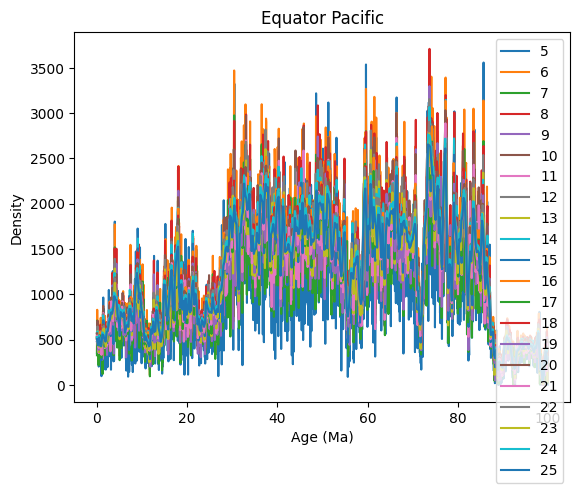

In [19]:
fig, ax = plt.subplots()

for window_size in range(start, end+1, step):

  density_name = 'density_' + str(window_size)

  ages = np.arange(0, 100, (100-0)/len(locals()[density_name]))

  sorted_density = locals()[density_name][np.argsort(ages)]

  ax.plot(ages, sorted_density, label=str(window_size))

ax.set_xlabel('Age (Ma)')
ax.set_ylabel('Density') 
ax.set_title('Equator Pacific')
ax.legend()

plt.show()

In [20]:
from scipy.interpolate import interp1d

start = 5  
end = 25
step = 1

# 定义共同年代坐标
ages = np.arange(0, 100, 1) 

# 遍历每个窗口
for window_size in range(start, end+1, step):

  density_name = 'density_' + str(window_size)
  density_interp_name = 'density_interp_' + str(window_size)

  # 生成原始年代坐标
  ages_orig = np.arange(0, 100, (100-0)/len(locals()[density_name]))

  loc = locals()
  
  # 原始密度
  density_orig = loc[density_name]

  # 插值函数
  interp_func = interp1d(ages_orig, density_orig, fill_value='extrapolate')

  # 在ages节点插值
  density_on_ages = interp_func(ages)
  loc[density_interp_name] = density_on_ages

In [21]:
df = pd.DataFrame(ages, columns=['ages'])

# 循环加入密度列
density_names = [f'density_interp_{w}' for w in range(5, 26, 1)]
for dens_name in density_names:
  df[dens_name] = locals()[dens_name]

# 设置年代坐标为索引  
df.set_index('ages', inplace=True)

In [22]:
df

,density_interp_5,density_interp_6,density_interp_7,density_interp_8,density_interp_9,density_interp_10,density_interp_11,density_interp_12,density_interp_13,density_interp_14,...,density_interp_16,density_interp_17,density_interp_18,density_interp_19,density_interp_20,density_interp_21,density_interp_22,density_interp_23,density_interp_24,density_interp_25
ages,,,,,,,,,,,,,,,,,,,,,
0,352.451293,381.686767,327.160086,571.784946,508.253286,525.302419,477.547653,574.773906,530.560528,568.038400,...,547.552061,515.343116,507.504336,480.793582,569.763060,542.631486,528.928804,505.931900,527.458891,506.360535
1,111.877175,351.410157,301.208706,354.401216,315.023303,378.965575,344.514160,401.055119,370.204726,310.243284,...,373.009693,351.067946,471.783341,446.952638,350.212160,333.535391,448.163523,428.678153,467.869014,449.154253
2,338.587522,450.102848,385.802441,529.352955,470.535960,468.550749,425.955227,525.557006,485.129544,506.439897,...,546.267273,514.133904,494.456973,468.432921,480.961737,458.058797,461.632199,441.561234,535.304263,513.892093
3,432.496702,739.756826,634.077280,513.165489,456.147101,428.130767,389.209789,679.658240,627.376837,617.783499,...,673.745061,634.112999,641.188039,607.441301,690.767584,657.873889,765.223822,731.953221,790.901324,759.265272
4,1328.073532,1456.958813,1248.821839,1334.680927,1186.383046,1280.432923,1164.029930,1165.011761,1075.395471,1057.687341,...,1119.538037,1053.682858,1150.930591,1090.355297,1177.868826,1121.779834,1139.977061,1090.412841,994.131572,954.366310
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,342.393985,499.635749,428.259213,484.814663,430.946367,486.354176,442.140160,487.599588,450.091927,500.108477,...,459.057116,432.053757,492.116135,466.215285,441.548059,420.521961,463.704675,443.543602,461.006661,442.566395
96,409.548019,544.209462,466.465253,482.670313,429.040279,522.952299,475.411181,499.660852,461.225402,454.114074,...,472.133139,444.360602,462.384038,438.048036,488.629377,465.361311,465.032497,444.813692,442.195480,424.507661
97,263.479825,375.746360,322.068308,388.476292,345.312260,336.130869,305.573517,337.856730,311.867751,356.554910,...,400.693396,377.123196,361.679657,342.643886,393.064249,374.346904,377.962350,361.529204,402.377667,386.282560


In [32]:
# 构建x, y
xt = np.log10(np.array([5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25]))
k = []

for i in range(len(df)):
  yi = np.log10(df.iloc[i, :])
  print(yi)  
  ki, _ = np.polyfit(xt, yi, 1)
  k.append(ki)

k = np.array(k)

density_interp_5     2.547099
density_interp_6     2.581707
density_interp_7     2.514760
density_interp_8     2.757233
density_interp_9     2.706080
density_interp_10    2.720409
density_interp_11    2.679017
density_interp_12    2.759497
density_interp_13    2.724735
density_interp_14    2.754378
density_interp_15    2.724414
density_interp_16    2.738425
density_interp_17    2.712096
density_interp_18    2.705440
density_interp_19    2.681959
density_interp_20    2.755694
density_interp_21    2.734505
density_interp_22    2.723397
density_interp_23    2.704092
density_interp_24    2.722189
density_interp_25    2.704460
Name: 0, dtype: float64
density_interp_5     2.048741
density_interp_6     2.545814
density_interp_7     2.478868
density_interp_8     2.549495
density_interp_9     2.498343
density_interp_10    2.578600
density_interp_11    2.537207
density_interp_12    2.603204
density_interp_13    2.568442
density_interp_14    2.491702
density_interp_15    2.461739
density_interp_1

In [39]:
# 计算上下包络线
kmax = []
kmin = [] 

for i in range(len(k)):
    if i == 0 or i == len(k)-1:
        kmax.append(k[i])
        kmin.append(k[i])

    else:
        # 对k的一个切片段直接求最大最小值
        kmax.append(np.max(k[i-1:i+2]))  
        kmin.append(np.min(k[i-1:i+2]))

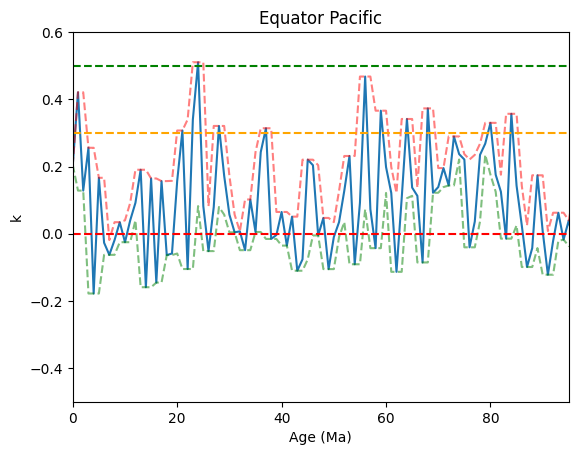

In [45]:
plt.plot(ages, k)
plt.plot(ages, kmax, '--', color='red', alpha=0.5)
plt.plot(ages, kmin, '--', color='green', alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.axhline(y=0.3, color='orange', linestyle='--')
plt.axhline(y=0.5, color='green', linestyle='--')


# 设置x轴范围
plt.xlim(0, 95)
# # 设置x轴范围
plt.ylim(-0.5, 0.6)

plt.xlabel('Age (Ma)')  
plt.ylabel('k')
plt.title('Equator Pacific')

plt.show()